In [1]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import itertools

Função para plotagem de box plot

In [2]:
def plot_box_plot(data_frame, X_variable, Y_variable, title, X_label, Y_label):
        
    sns.boxplot(
        data=data_frame,
        x=X_variable,
        y=Y_variable
    )

    plt.title(title)
    plt.xlabel(X_label)
    plt.ylabel(Y_label)
    plt.grid(True, axis="y")
    plt.tight_layout()
    plt.show()

In [3]:
def plot_boxplot_metrics(df, parameter_column, title=None):

    metrics = [
        ("loss", "Loss"),
        ("accuracy", "Accuracy (%)"),
        ("f1", "F1-score")
    ]

    groups = df.groupby(parameter_column)

    labels = [str(name) for name, _ in groups]

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    for ax, (metric, ylabel) in zip(axes, metrics):

        data = [
            group[metric].values
            for _, group in df.groupby(parameter_column)
        ]

        ax.boxplot(
            data,
            tick_labels=labels
        )

        ax.set_title(ylabel)
        ax.set_xlabel(parameter_column)
        ax.set_ylabel(ylabel)
        ax.grid(True, axis="y")

        if metric == "accuracy":
            ax.set_ylim(0, 100)

        elif metric == "f1":
            ax.set_ylim(0, 1)

    if title:
        fig.suptitle(title)

    plt.tight_layout()
    plt.show()

Função para plotagem de gráfico de linhas

In [4]:
def plot_grafico_linhas(data_frame, title, X_variable, Y_variable, X_label, Y_label, scale_X=0, scale_Y=100):

    fig, axes = plt.subplots(1,len(data_frame),figsize=(12, 5))
    fig.suptitle(title)

    for ax, (name, data) in zip(axes, grouped):

        ax.plot(data[X_variable],data[Y_variable],marker="o")

        ax.set_title(name)
        ax.set_xlabel(X_label)
        ax.set_ylabel(Y_label)
        ax.set_ylim(scale_X, scale_Y)
        ax.grid(True)

    plt.tight_layout()
    plt.show()

Grafico de linhas em conjunto com varias métricas

In [5]:
def plot_grafico_linha_metricas(
        grouped,          # lista de tuplas (DataFrame)
        title,            # título da figura (suptitle)
        X_variable,       # nome da coluna que será usada como eixo X
        Y_vars,           # lista de nomes de colunas que serão plotadas
        X_label,          # rótulo do eixo X
        Y_labels,         # rótulo de cada subplot
        scale_X=0,        # valor mínimo do eixo X (opcional)
        scale_Ys=None,    # lista de tuplas (ymin, ymax) ou número único
        figsize=(5, 5),   # tamanho da figura (largura, altura)
        markers=None,     # lista de marcadores (um por grupo) ou string
        colors=None       # lista de cores ou nome de colormap
    ):
   
    n_vars = len(Y_vars)

    # Cria subplots: 1 linha, n_vars colunas
    fig, axes = plt.subplots(1, n_vars, figsize=(figsize[0] * n_vars, figsize[1]))

    # Se só houver 1 subplot, garante que axes seja lista
    if n_vars == 1:
        axes = [axes]

    fig.suptitle(title, fontsize=14, y=1.02)

    if scale_Ys is None:
        scale_Ys = [(scale_X, 100)] * n_vars
    else:
        if isinstance(scale_Ys, (int, float)):
            scale_Ys = [(scale_X, scale_Ys)] * n_vars
        else:
            
            new_scale = []
            for s in scale_Ys:
                if isinstance(s, tuple):
                    new_scale.append(s)
                else:
                    new_scale.append((scale_X, s))
            scale_Ys = new_scale

  
    n_groups = len(grouped)

    if markers is None:
        markers = ['o'] * n_groups
    elif isinstance(markers, str):
        markers = [markers] * n_groups
    else:
        markers = list(itertools.islice(itertools.cycle(markers), n_groups))

   
    if colors is None:
        # Colormap padrão tab20 com nº de grupos
        cmap = plt.get_cmap('tab20', n_groups)
        colors = [cmap(i) for i in range(n_groups)]
    elif isinstance(colors, str):
        
        cmap = plt.get_cmap(colors, n_groups)
        colors = [cmap(i) for i in range(n_groups)]
    else:
        
        colors = list(itertools.islice(itertools.cycle(colors), n_groups))

    for ax, Y, Y_label, (ymin, ymax) in zip(axes, Y_vars, Y_labels, scale_Ys):
        for (grp_name, df), marker, color in zip(grouped, markers, colors):
            ax.plot(df[X_variable], df[Y], marker=marker, color=color,
                    label=grp_name, linewidth=1.5)

        ax.set_title(Y_label)
        ax.set_xlabel(X_label)
        ax.set_ylabel(Y_label)
        ax.set_ylim(ymin, ymax)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


DataFrames das métricas

In [6]:
batch_sizes_metrics_pd = pd.read_csv("../resultados/hiperparametros/batch_sizes_metrics_cv.csv")
learning_rates_metrics_pd = pd.read_csv("../resultados/hiperparametros/learning_rates_metrics_cv.csv")
pooling_metrics_pd = pd.read_csv("../resultados/hiperparametros/poolings_metrics_cv.csv")

Análise de variação dos Poolings

In [7]:
pooling_metrics_pd.drop(columns=["fold"]).groupby("poolings").agg({
    "loss": ["mean", "std"],
    "accuracy": ["mean", "std"],
    "f1": ["mean", "std"]
})

loss             accuracy                  f1          
              mean       std       mean       std      mean       std
poolings                                                             
avg       0.343117  0.293313  86.371795  9.152490  0.854554  0.103427
max       0.469916  0.104532  86.435897  5.170618  0.865494  0.044102

Gráficos de Linha

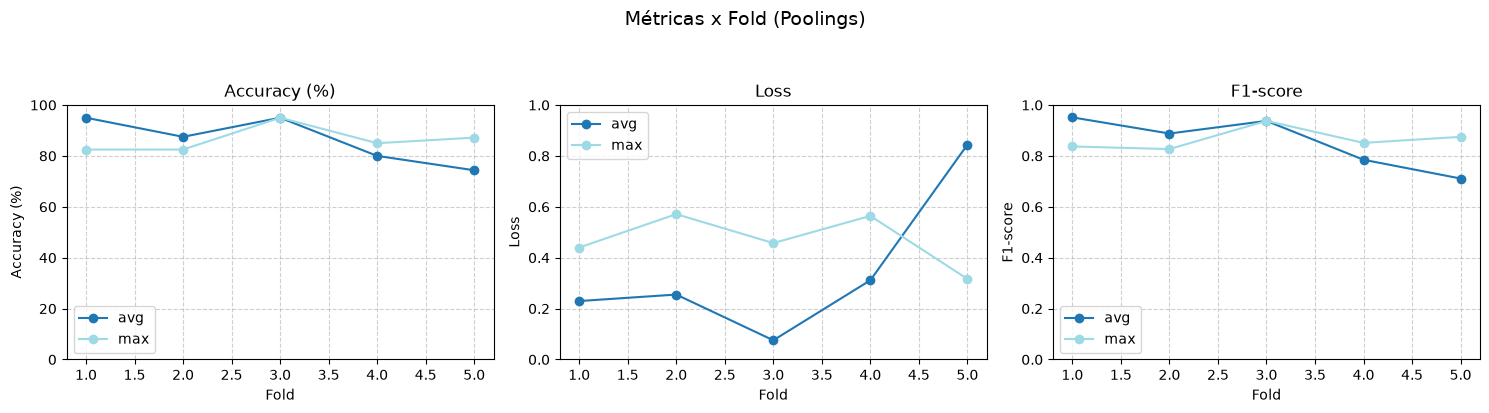

In [ ]:
grouped = pooling_metrics_pd.groupby("poolings")

plot_grafico_linha_metricas(
    grouped=grouped,
    title="Métricas x Fold (Poolings)",
    X_variable="fold",
    Y_vars=["accuracy", "loss", "f1"],
    X_label="Fold",
    Y_labels=["Accuracy (%)", "Loss", "F1-score"],
    scale_X=0,
    scale_Ys=[(0, 100), (0, 1), (0, 1)],
    figsize=(5, 4)
)


BoxPlot para análise de distribuição dos dados

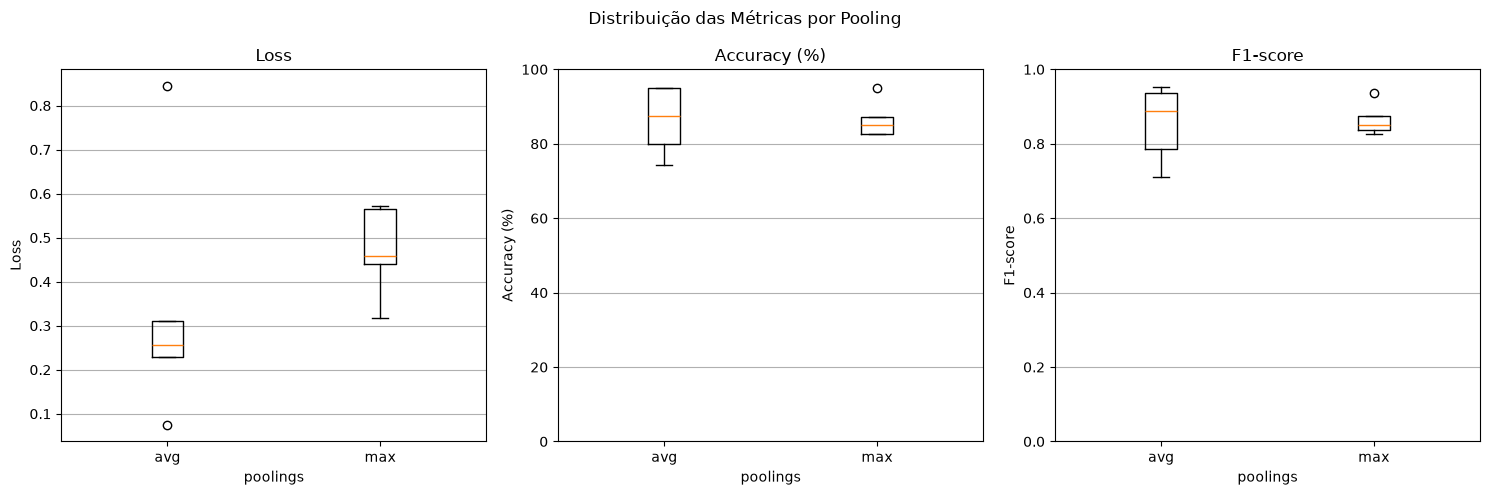

In [9]:
plot_boxplot_metrics(pooling_metrics_pd, "poolings", title="Distribuição das Métricas por Pooling")

Após análise das métricas estatísitcas apresentadas, compreende-se que o pooling max.0005 se mostrou mais apropriado para esta tarefa. Assim, será analisado o gráfico de curva de taxas de aprendizado e perda para verificar a existência de overfiting no modelo

In [10]:
pooling_predictions_DF = pd.read_csv("../resultados/hiperparametros/poolings_predictions_cv.csv")
pooling_predictions_DF_max = pooling_predictions_DF[pooling_predictions_DF["pooling"] == "max"]

Gráfico Fold 1 - Pooling Max

In [11]:
pooling_predictions_DF_max

,fold,pooling,sample,true_label,predicted_label,prob_0,prob_1,prob_2,prob_3
0,1,max,0,0,0,9.401993e-01,7.485102e-04,5.852284e-02,0.000529
1,1,max,1,0,2,1.523188e-01,2.075993e-03,6.473044e-01,0.198301
2,1,max,2,0,2,6.481633e-02,1.042511e-03,9.338404e-01,0.000301
3,1,max,3,0,2,2.411335e-01,2.793938e-03,7.462196e-01,0.009853
4,1,max,4,0,0,4.748987e-01,2.627051e-03,1.731617e-01,0.349313
...,...,...,...,...,...,...,...,...,...
194,5,max,34,3,3,3.247111e-06,2.682853e-05,5.066752e-07,0.999969
195,5,max,35,3,3,1.212993e-05,1.775851e-04,1.314945e-04,0.999679
196,5,max,36,3,3,3.614343e-03,2.963453e-04,3.421781e-03,0.992668
197,5,max,37,3,3,1.639896e-04,1.137185e-05,2.772655e-05,0.999797


Análise de variação dos Batch Sizes

In [12]:
batch_sizes_metrics_pd.drop(columns=["fold"]).groupby("batch_sizes").agg({
    "loss": ["mean", "std"],
    "accuracy": ["mean", "std"],
    "f1": ["mean", "std"]
})

loss             accuracy                   f1          
                 mean       std       mean        std      mean       std
batch_sizes                                                              
4            0.859510  1.310777  79.474359  23.788331  0.781779  0.266193
8            0.805255  0.971456  78.448718  17.600818  0.782792  0.172194
16           0.189099  0.148250  92.974359   4.795840  0.927832  0.044288

Gráficos de Linha

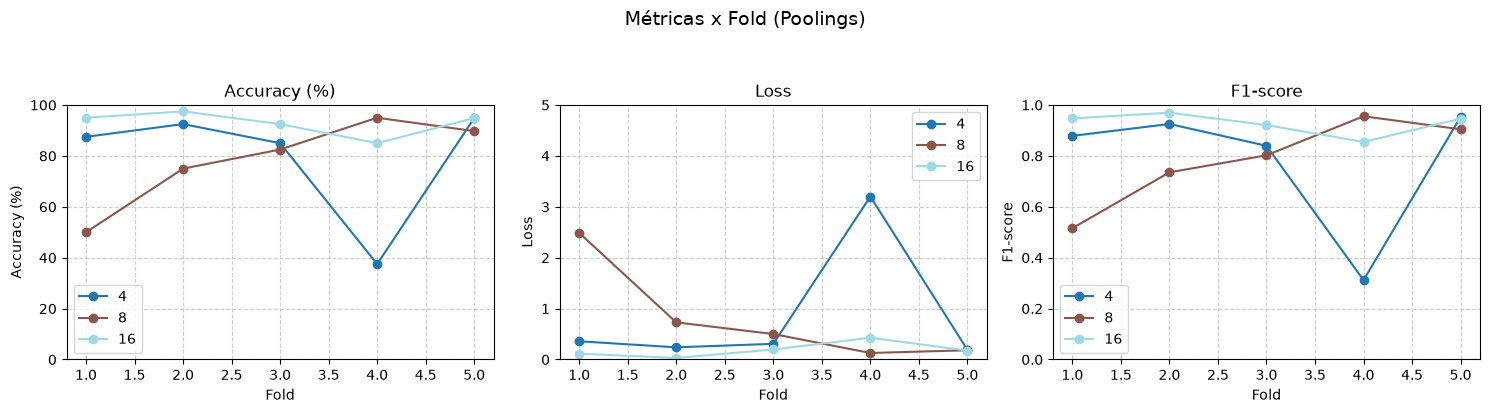

In [13]:
grouped = batch_sizes_metrics_pd.groupby("batch_sizes")
plot_grafico_linha_metricas(
    grouped=grouped,
    title="Métricas x Fold (Poolings)",
    X_variable="fold",
    Y_vars=["accuracy", "loss", "f1"],
    X_label="Fold",
    Y_labels=["Accuracy (%)", "Loss", "F1‑score"],
    scale_X=0,
    scale_Ys=[(0, 100), (0, 5), (0, 1)],
    figsize=(5, 4)
)


BoxPlot para análise de distribuição dos dados

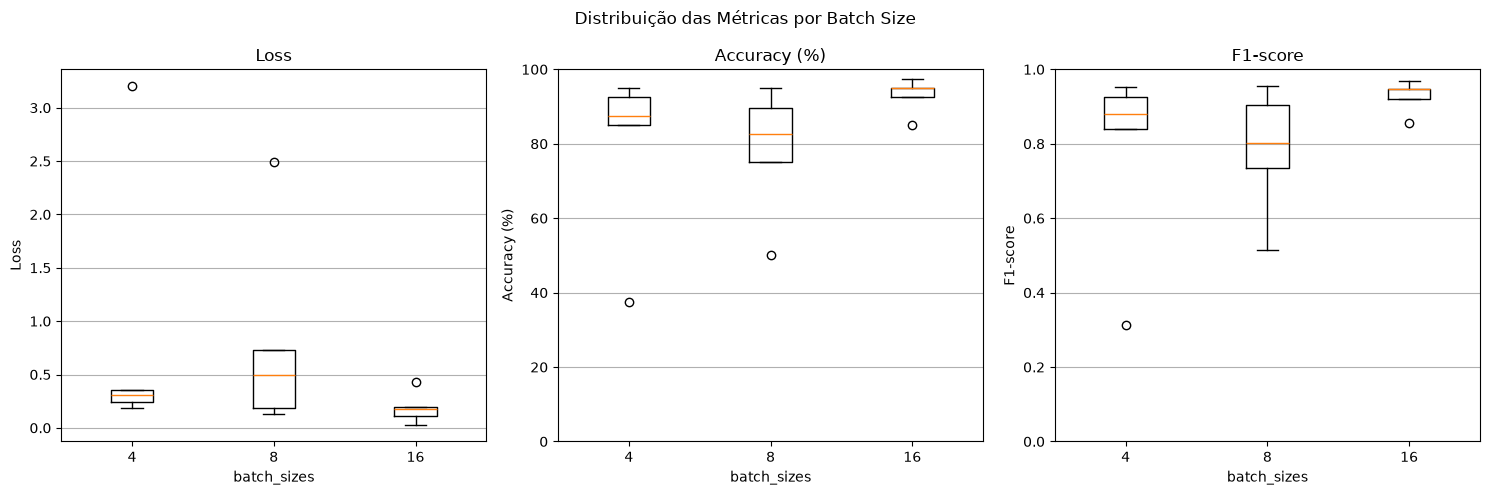

In [14]:
plot_boxplot_metrics(batch_sizes_metrics_pd, "batch_sizes", title="Distribuição das Métricas por Batch Size")

Análise de variação do Learning Rate

In [15]:
learning_rates_metrics_pd.drop(columns=["fold"]).groupby("learning_rate").agg({
    "loss": ["mean", "std"],
    "accuracy": ["mean", "std"],
    "f1": ["mean", "std"]
})

loss             accuracy                   f1          
                   mean       std       mean        std      mean       std
learning_rate                                                              
0.0001         0.142068  0.113605  96.448718   4.283279  0.964605  0.040318
0.0005         0.060485  0.026140  97.987179   1.125543  0.980413  0.011429
0.0010         0.509518  0.394142  86.974359   5.925830  0.867828  0.056560
0.0100         1.699807  1.359735  51.730769  17.364224  0.424384  0.162600

Gráficos de Linhas

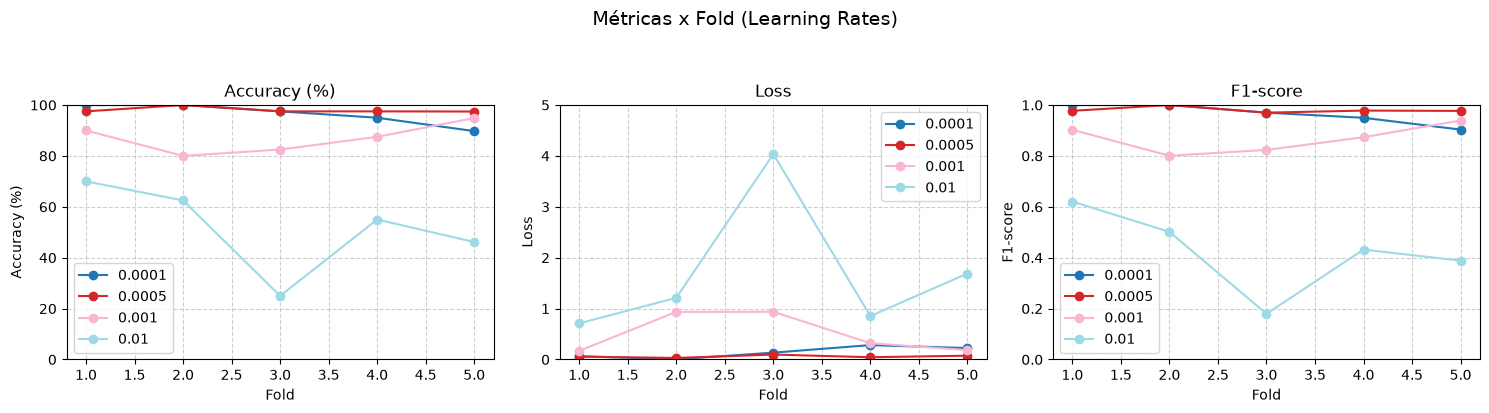

In [16]:
grouped = learning_rates_metrics_pd.groupby("learning_rate")
plot_grafico_linha_metricas(
    grouped=grouped,
    title="Métricas x Fold (Learning Rates)",
    X_variable="fold",
    Y_vars=["accuracy", "loss", "f1"],
    X_label="Fold",
    Y_labels=["Accuracy (%)", "Loss", "F1-score"],
    scale_X=0,
    scale_Ys=[(0, 100), (0, 5), (0, 1)],
    figsize=(5, 4)
)

BoxPlot para análise de distribuição dos dados

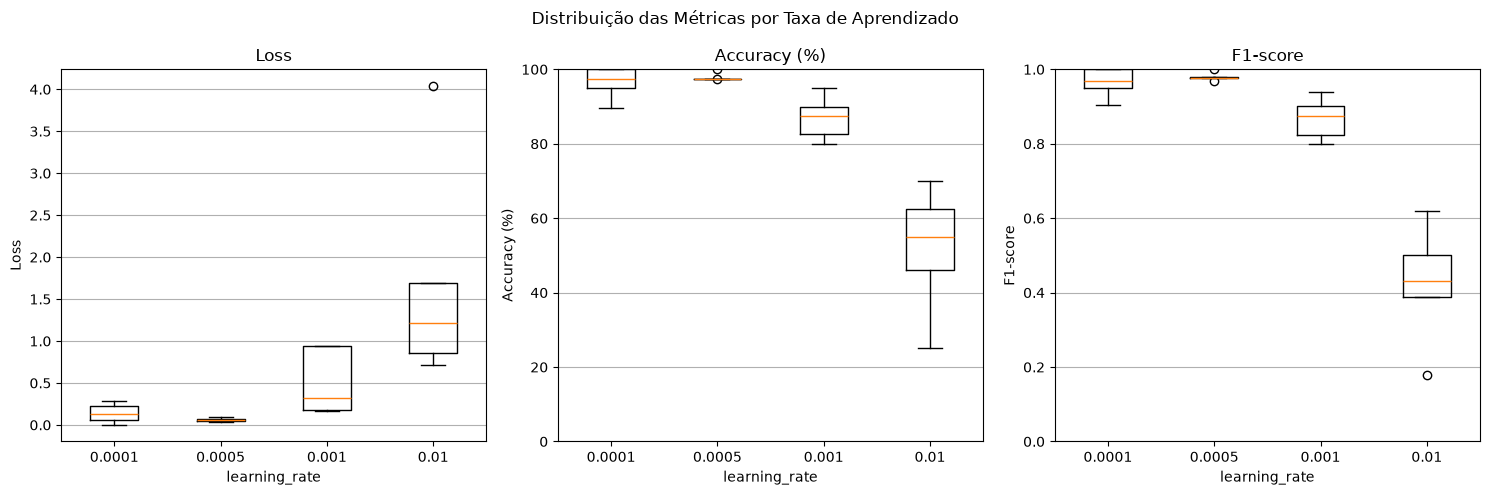

In [17]:
plot_boxplot_metrics(learning_rates_metrics_pd, "learning_rate", title="Distribuição das Métricas por Taxa de Aprendizado")

Após análise das métricas estatísitcas apresentadas, compreende-se que o learning rate de 0.0005 se mostrou mais apropriado para esta tarefa. Assim, será analisado o gráfico de curva de taxas de aprendizado e perda para verificar a existência de overfiting no modelo

In [18]:
learning_rate_predictions_DF = pd.read_csv("../resultados/hiperparametros/learning_rates_metrics_cv.csv")